In [1]:
from itertools import islice
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


def uniform_triangle(u, v):
    while True:
        s = np.random.uniform()
        t = np.random.uniform()
        in_triangle = s + t <= 1
        p = s * u + t * v if in_triangle else (1 - s) * u + (1 - t) * v
        yield p


triangle_set1 = [
    np.array([[0, 0], [0.25, 0.25], [0, 0.5]]),
    np.array([[0.5, 0.5], [0.25, 0.25], [0, 0.5]]),
    np.array([[0.5, 0.5], [0.25, 0.75], [0, 0.5]]),
    np.array([[0, 1], [0.25, 0.75], [0, 0.5]]),
]
triangle_set2 = [np.concatenate((a[:, 1:2], a[:, 0:1]), axis=1) for a in triangle_set1]

triangle_set = triangle_set1 + triangle_set2

[[0.08333333 0.25      ]
 [0.25       0.41666667]
 [0.25       0.58333333]
 [0.08333333 0.75      ]
 [0.25       0.08333333]
 [0.41666667 0.25      ]
 [0.58333333 0.25      ]
 [0.75       0.08333333]]
[[0.        ]
 [0.14285714]
 [0.28571429]
 [0.42857143]
 [0.57142857]
 [0.71428571]
 [0.85714286]
 [1.        ]]


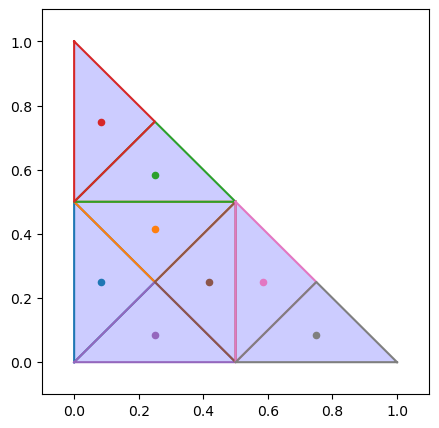

In [2]:
np.random.seed(42)

fig, ax = plt.subplots(figsize=(5, 5))
point_total = []

for triangle in triangle_set:
    # draw the triangle
    x_coords, y_coords = zip(*triangle)
    # Close the triangle by adding the first vertex at the end
    x_coords += (x_coords[0],)
    y_coords += (y_coords[0],)

    # Create the plot
    ax.plot(x_coords, y_coords)  # 'o' for circle markers at the vertices
    ax.fill(
        x_coords, y_coords, "b", alpha=0.2
    )  # Fill the triangle with a blue color and some transparency

    it = uniform_triangle(
        triangle[1] - triangle[0],
        triangle[2] - triangle[0],
    )
    # points = np.array(list(islice(it, 0, 7))) + triangle[0]
    points = triangle.mean(axis=0).reshape(-1, 2)

    ax.scatter(points[:, 0], points[:, 1], s=20)
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(-0.1, 1.1)

    point_total.append(points)
point_total = np.concatenate(point_total)

array = np.linspace(0, 1, 9)
# mean_values = np.array([(array[i] + array[i + 1]) / 2 for i in range(len(array) - 1)]).reshape(-1,1)

mean_values = np.linspace(0, 1, 8).reshape(-1, 1)
print(point_total)
print(mean_values)

In [3]:
metal_combo = np.array(
    [
        ["Co", "Cd"],
    ]
)

np.random.seed(42)
candidates_total = []
for metal_combo_temp in metal_combo:
    a_temp = point_total.copy()
    b_temp = mean_values.copy()
    c_temp = mean_values.copy()
    np.random.shuffle(a_temp)
    np.random.shuffle(b_temp)
    np.random.shuffle(c_temp)
    candidates = np.around(
        np.concatenate((a_temp * 9.5 + 0.5, b_temp * 5, c_temp * 5), axis=1), 2
    )

    water = (20 - candidates.sum(axis=1)).reshape(-1, 1)
    candidates = np.concatenate((candidates, water), axis=1)
    candidates_total.append(candidates)
    print(metal_combo_temp)
    print(candidates)

['Co' 'Cd']
[[ 2.88  4.46  2.14  0.   10.52]
 [ 4.46  2.88  5.    4.29  3.37]
 [ 1.29  2.88  0.    2.14 13.69]
 [ 7.62  1.29  2.86  0.71  7.52]
 [ 2.88  6.04  3.57  2.86  4.65]
 [ 2.88  1.29  1.43  3.57 10.83]
 [ 1.29  7.62  0.71  1.43  8.95]
 [ 6.04  2.88  4.29  5.    1.79]]


In [4]:
len(candidates_total[0])

8

In [4]:
_all_candidates = []
# export the json file
# set a repeat experiment as a reference
repeat_exp = pd.DataFrame(
    {
        "substance1": ["Co"],
        "volume1": [4.0],
        "substance2": ["Cd"],
        "volume2": [4.0],
        "substance3": ["Na3Cit"],
        "volume3": [3.0],
        "substance4": ["H3BO3"],
        "volume4": [4.0],
        "substance5": ["water"],
        "volume5": [5.0],
        
        "syn_completed": ["None"],
        "storage_location": ["None"],
        "in_storage": ["None"],
        "cat_completed": ["None"], 
        
        "lsv_overpotential_-0.01": ["None"],
        "lsv_overpotential_-0.02": ["None"],
        "lsv_overpotential_-0.03": ["None"],
        "lsv_overpotential_-0.04": ["None"],
        "lsv_overpotential_-0.05": ["None"],
    }
)

repeat_index = [0]

# write the new candidates to the excel for the closed-loop discovery
exp_data_out = {}
exp_data_out["substance1"] = []
exp_data_out["volume1"] = []
exp_data_out["substance2"] = []
exp_data_out["volume2"] = []
exp_data_out["substance3"] = []
exp_data_out["volume3"] = []
exp_data_out["substance4"] = []
exp_data_out["volume4"] = []
exp_data_out["substance5"] = []
exp_data_out["volume5"] = []

exp_data_out["syn_completed"] = []
exp_data_out["storage_location"] = []
exp_data_out["in_storage"] = []

exp_data_out["cat_completed"] = []
exp_data_out["lsv_overpotential_-0.01"] = []
exp_data_out["lsv_overpotential_-0.02"] = []
exp_data_out["lsv_overpotential_-0.03"] = []
exp_data_out["lsv_overpotential_-0.04"] = []
exp_data_out["lsv_overpotential_-0.05"] = []

exp_data_out = pd.DataFrame(exp_data_out)

for candidate_index in range(len(candidates_total[0])):
    metal_index = 0
    # if len(exp_data_out)%4 ==0:
    #     exp_data_out = pd.concat((exp_data_out, repeat_exp), ignore_index=True)

    temp = pd.DataFrame(
        {
            "substance1": [metal_combo[metal_index][0]],
            "volume1": [candidates_total[metal_index][candidate_index][0]],
            "substance2": [metal_combo[metal_index][1]],
            "volume2": [candidates_total[metal_index][candidate_index][1]],
            "substance3": "Na3Cit",
            "volume3": [candidates_total[metal_index][candidate_index][2]],
            "substance4": "H3BO3",
            "volume4": [candidates_total[metal_index][candidate_index][3]],
            "substance5": "water",
            "volume5": [candidates_total[metal_index][candidate_index][4]],
            "syn_completed": ["None"],
            "storage_location": ["None"],
            "in_storage": ["None"],
            "cat_completed": ["None"], 
            "lsv_overpotential_-0.01": ["None"],
            "lsv_overpotential_-0.02": ["None"],
            "lsv_overpotential_-0.03": ["None"],
            "lsv_overpotential_-0.04": ["None"],
            "lsv_overpotential_-0.05": ["None"],
        }
    )

    for repeat in range(1):
        exp_data_out = pd.concat((exp_data_out, temp), ignore_index=True)
            
    if len(exp_data_out) in repeat_index:
        exp_data_out = pd.concat((exp_data_out, repeat_exp), ignore_index=True)
    display(exp_data_out)
    _all_candidates.append(exp_data_out)
exp_data_out.to_json(f"./initial_sampling_Co_Cd.json")

,substance1,volume1,substance2,volume2,substance3,volume3,substance4,volume4,substance5,volume5,syn_completed,storage_location,in_storage,cat_completed,lsv_overpotential_-0.01,lsv_overpotential_-0.02,lsv_overpotential_-0.03,lsv_overpotential_-0.04,lsv_overpotential_-0.05
0,Co,2.88,Cd,4.46,Na3Cit,2.14,H3BO3,0.0,water,10.52,None,None,None,None,None,None,None,None,None


,substance1,volume1,substance2,volume2,substance3,volume3,substance4,volume4,substance5,volume5,syn_completed,storage_location,in_storage,cat_completed,lsv_overpotential_-0.01,lsv_overpotential_-0.02,lsv_overpotential_-0.03,lsv_overpotential_-0.04,lsv_overpotential_-0.05
0,Co,2.88,Cd,4.46,Na3Cit,2.14,H3BO3,0.00,water,10.52,None,None,None,None,None,None,None,None,None
1,Co,4.46,Cd,2.88,Na3Cit,5.00,H3BO3,4.29,water,3.37,None,None,None,None,None,None,None,None,None


,substance1,volume1,substance2,volume2,substance3,volume3,substance4,volume4,substance5,volume5,syn_completed,storage_location,in_storage,cat_completed,lsv_overpotential_-0.01,lsv_overpotential_-0.02,lsv_overpotential_-0.03,lsv_overpotential_-0.04,lsv_overpotential_-0.05
0,Co,2.88,Cd,4.46,Na3Cit,2.14,H3BO3,0.00,water,10.52,None,None,None,None,None,None,None,None,None
1,Co,4.46,Cd,2.88,Na3Cit,5.00,H3BO3,4.29,water,3.37,None,None,None,None,None,None,None,None,None
2,Co,1.29,Cd,2.88,Na3Cit,0.00,H3BO3,2.14,water,13.69,None,None,None,None,None,None,None,None,None


,substance1,volume1,substance2,volume2,substance3,volume3,substance4,volume4,substance5,volume5,syn_completed,storage_location,in_storage,cat_completed,lsv_overpotential_-0.01,lsv_overpotential_-0.02,lsv_overpotential_-0.03,lsv_overpotential_-0.04,lsv_overpotential_-0.05
0,Co,2.88,Cd,4.46,Na3Cit,2.14,H3BO3,0.00,water,10.52,None,None,None,None,None,None,None,None,None
1,Co,4.46,Cd,2.88,Na3Cit,5.00,H3BO3,4.29,water,3.37,None,None,None,None,None,None,None,None,None
2,Co,1.29,Cd,2.88,Na3Cit,0.00,H3BO3,2.14,water,13.69,None,None,None,None,None,None,None,None,None
3,Co,7.62,Cd,1.29,Na3Cit,2.86,H3BO3,0.71,water,7.52,None,None,None,None,None,None,None,None,None


,substance1,volume1,substance2,volume2,substance3,volume3,substance4,volume4,substance5,volume5,syn_completed,storage_location,in_storage,cat_completed,lsv_overpotential_-0.01,lsv_overpotential_-0.02,lsv_overpotential_-0.03,lsv_overpotential_-0.04,lsv_overpotential_-0.05
0,Co,2.88,Cd,4.46,Na3Cit,2.14,H3BO3,0.00,water,10.52,None,None,None,None,None,None,None,None,None
1,Co,4.46,Cd,2.88,Na3Cit,5.00,H3BO3,4.29,water,3.37,None,None,None,None,None,None,None,None,None
2,Co,1.29,Cd,2.88,Na3Cit,0.00,H3BO3,2.14,water,13.69,None,None,None,None,None,None,None,None,None
3,Co,7.62,Cd,1.29,Na3Cit,2.86,H3BO3,0.71,water,7.52,None,None,None,None,None,None,None,None,None
4,Co,2.88,Cd,6.04,Na3Cit,3.57,H3BO3,2.86,water,4.65,None,None,None,None,None,None,None,None,None


,substance1,volume1,substance2,volume2,substance3,volume3,substance4,volume4,substance5,volume5,syn_completed,storage_location,in_storage,cat_completed,lsv_overpotential_-0.01,lsv_overpotential_-0.02,lsv_overpotential_-0.03,lsv_overpotential_-0.04,lsv_overpotential_-0.05
0,Co,2.88,Cd,4.46,Na3Cit,2.14,H3BO3,0.00,water,10.52,None,None,None,None,None,None,None,None,None
1,Co,4.46,Cd,2.88,Na3Cit,5.00,H3BO3,4.29,water,3.37,None,None,None,None,None,None,None,None,None
2,Co,1.29,Cd,2.88,Na3Cit,0.00,H3BO3,2.14,water,13.69,None,None,None,None,None,None,None,None,None
3,Co,7.62,Cd,1.29,Na3Cit,2.86,H3BO3,0.71,water,7.52,None,None,None,None,None,None,None,None,None
4,Co,2.88,Cd,6.04,Na3Cit,3.57,H3BO3,2.86,water,4.65,None,None,None,None,None,None,None,None,None
5,Co,2.88,Cd,1.29,Na3Cit,1.43,H3BO3,3.57,water,10.83,None,None,None,None,None,None,None,None,None


,substance1,volume1,substance2,volume2,substance3,volume3,substance4,volume4,substance5,volume5,syn_completed,storage_location,in_storage,cat_completed,lsv_overpotential_-0.01,lsv_overpotential_-0.02,lsv_overpotential_-0.03,lsv_overpotential_-0.04,lsv_overpotential_-0.05
0,Co,2.88,Cd,4.46,Na3Cit,2.14,H3BO3,0.00,water,10.52,None,None,None,None,None,None,None,None,None
1,Co,4.46,Cd,2.88,Na3Cit,5.00,H3BO3,4.29,water,3.37,None,None,None,None,None,None,None,None,None
2,Co,1.29,Cd,2.88,Na3Cit,0.00,H3BO3,2.14,water,13.69,None,None,None,None,None,None,None,None,None
3,Co,7.62,Cd,1.29,Na3Cit,2.86,H3BO3,0.71,water,7.52,None,None,None,None,None,None,None,None,None
4,Co,2.88,Cd,6.04,Na3Cit,3.57,H3BO3,2.86,water,4.65,None,None,None,None,None,None,None,None,None
5,Co,2.88,Cd,1.29,Na3Cit,1.43,H3BO3,3.57,water,10.83,None,None,None,None,None,None,None,None,None
6,Co,1.29,Cd,7.62,Na3Cit,0.71,H3BO3,1.43,water,8.95,None,None,None,None,None,None,None,None,None


,substance1,volume1,substance2,volume2,substance3,volume3,substance4,volume4,substance5,volume5,syn_completed,storage_location,in_storage,cat_completed,lsv_overpotential_-0.01,lsv_overpotential_-0.02,lsv_overpotential_-0.03,lsv_overpotential_-0.04,lsv_overpotential_-0.05
0,Co,2.88,Cd,4.46,Na3Cit,2.14,H3BO3,0.00,water,10.52,None,None,None,None,None,None,None,None,None
1,Co,4.46,Cd,2.88,Na3Cit,5.00,H3BO3,4.29,water,3.37,None,None,None,None,None,None,None,None,None
2,Co,1.29,Cd,2.88,Na3Cit,0.00,H3BO3,2.14,water,13.69,None,None,None,None,None,None,None,None,None
3,Co,7.62,Cd,1.29,Na3Cit,2.86,H3BO3,0.71,water,7.52,None,None,None,None,None,None,None,None,None
4,Co,2.88,Cd,6.04,Na3Cit,3.57,H3BO3,2.86,water,4.65,None,None,None,None,None,None,None,None,None
5,Co,2.88,Cd,1.29,Na3Cit,1.43,H3BO3,3.57,water,10.83,None,None,None,None,None,None,None,None,None
6,Co,1.29,Cd,7.62,Na3Cit,0.71,H3BO3,1.43,water,8.95,None,None,None,None,None,None,None,None,None
7,Co,6.04,Cd,2.88,Na3Cit,4.29,H3BO3,5.00,water,1.79,None,None,None,None,None,None,None,None,None


In [6]:
2.88+4.46+2.14+10.52

20.0

In [7]:
candidates_total

[array([[ 2.88,  4.46,  2.14,  0.  , 10.52],
        [ 4.46,  2.88,  5.  ,  4.29,  3.37],
        [ 1.29,  2.88,  0.  ,  2.14, 13.69],
        [ 7.62,  1.29,  2.86,  0.71,  7.52],
        [ 2.88,  6.04,  3.57,  2.86,  4.65],
        [ 2.88,  1.29,  1.43,  3.57, 10.83],
        [ 1.29,  7.62,  0.71,  1.43,  8.95],
        [ 6.04,  2.88,  4.29,  5.  ,  1.79]])]